Ridge Classifier

**Algorithm:** Ridge Classifier (L2-penalised linear model via regression)  
**Features:** TF-IDF (50K unigrams + bigrams)  
Ridge Classifier solves a multiclass ridge regression problem and predicts the class with highest score. It is faster than logistic regression and often competitive.

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
from utils import (setup_paths, evaluate_and_print, plot_confusion_matrix,
                   plot_roc_curve, plot_pr_curve, plot_learning_curve)
from sklearn.metrics import accuracy_score
BASE_DIR, FIGURES_DIR = setup_paths()

In [2]:
from preprocess import load_all_datasets, get_train_test_split
df = load_all_datasets()
X_train, X_test, y_train, y_test = get_train_test_split(df)
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1,2), sublinear_tf=True, min_df=2, max_df=0.95)
X_tr = tfidf.fit_transform(X_train)
X_te = tfidf.transform(X_test)
print(f'Train: {len(X_train):,}  |  Test: {len(X_test):,}')


  LOADING ALL DATASETS
  [1/5] Loading ISOT Dataset...
      Loaded 44,898 records  (Fake=23,481  Real=21,417)
  [2/5] Loading FakeNewsNet Dataset...
      Loaded 23,196 records  (Fake=5,755  Real=17,441)
  [3/5] Loading LIAR Dataset...
      Loaded 12,791 records  (Fake=5,657  Real=7,134)
  [4/5] Loading MultiFC Dataset...
      Loaded 31,921 records  (Fake=13,980  Real=17,941)
  [5/5] Loading BuzzFeed Dataset...
      Loaded 2,282 records  (Fake=613  Real=1,669)

  Combined total   : 115,088 records
  Fake (0)         : 49,486
  Real (1)         : 65,602

  Cleaning text...
  After clean+dedup: 104,521 records

  Source distribution:
source
ISOT           38826
MultiFC        31919
FakeNewsNet    21046
LIAR           12726
BuzzFeed           4
Train: 83,616  |  Test: 20,905


In [3]:
from sklearn.linear_model import RidgeClassifier
MODEL_NAME = 'Ridge Classifier'
model = RidgeClassifier()
t0 = time.time()
model.fit(X_tr, y_train)
train_time = time.time() - t0
print(f'Training completed in {train_time:.2f}s')

Training completed in 2.50s


In [4]:
metrics, y_pred, y_prob = evaluate_and_print(model, X_te, y_test, MODEL_NAME, train_time)


  Ridge Classifier — Evaluation Results
  Accuracy          : 0.8306
  Precision         : 0.8302
  Recall            : 0.8306
  F1 Score          : 0.8290
  AUC-ROC           : 0.9130
  Train Time (s)    : 2.50s

              precision    recall  f1-score   support

    Fake (0)       0.82      0.74      0.78      8532
    Real (1)       0.83      0.89      0.86     12373

    accuracy                           0.83     20905
   macro avg       0.83      0.82      0.82     20905
weighted avg       0.83      0.83      0.83     20905



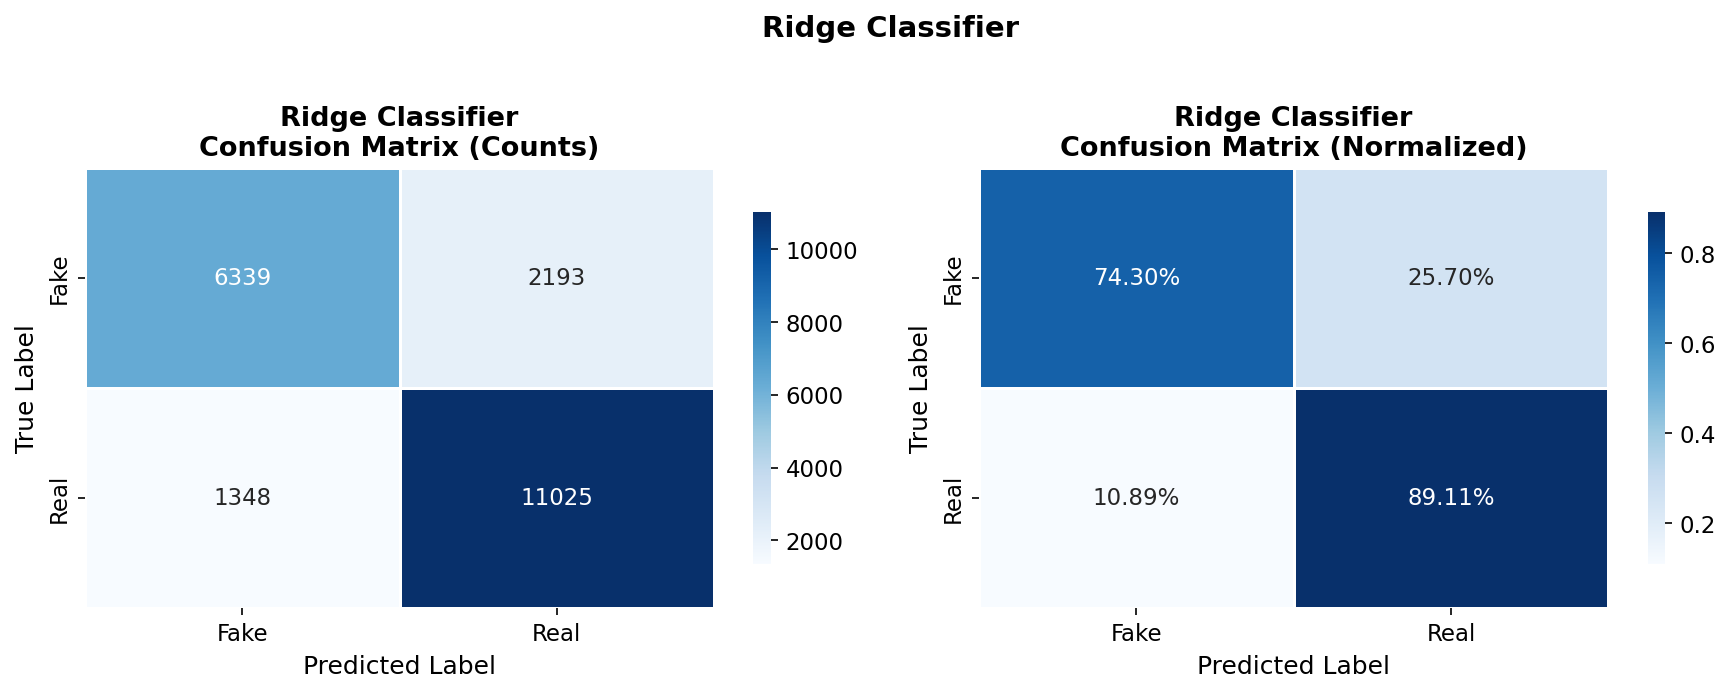

In [5]:
plot_confusion_matrix(y_test, y_pred, MODEL_NAME, FIGURES_DIR)

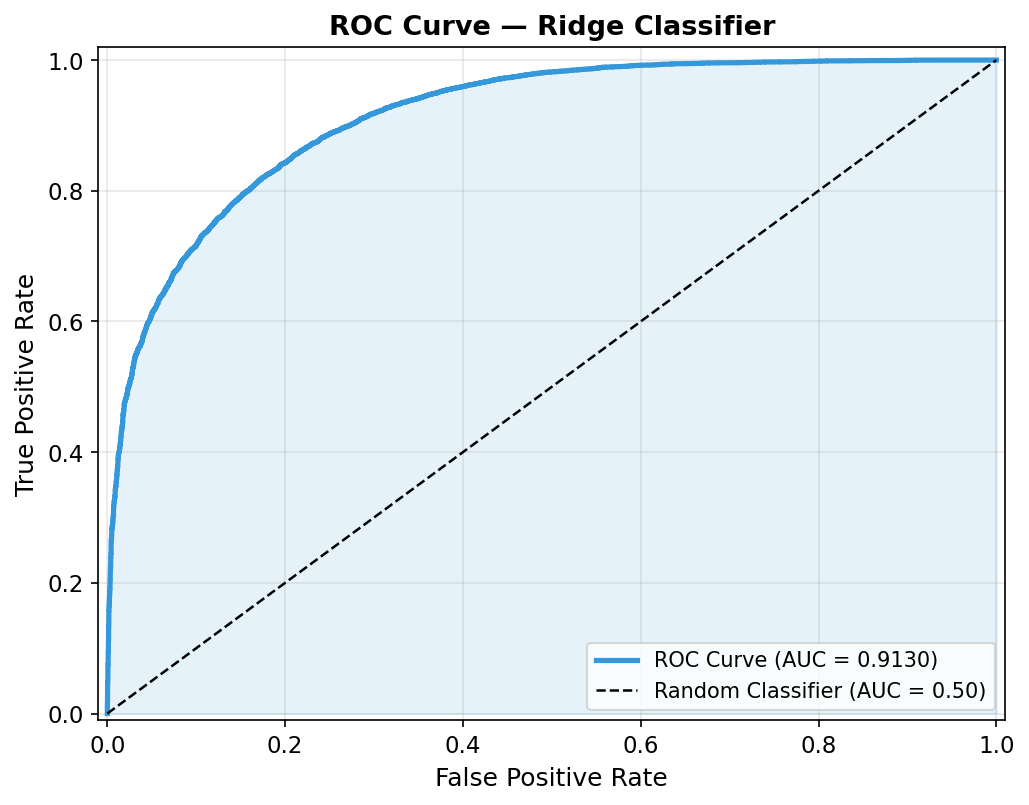

In [6]:
plot_roc_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

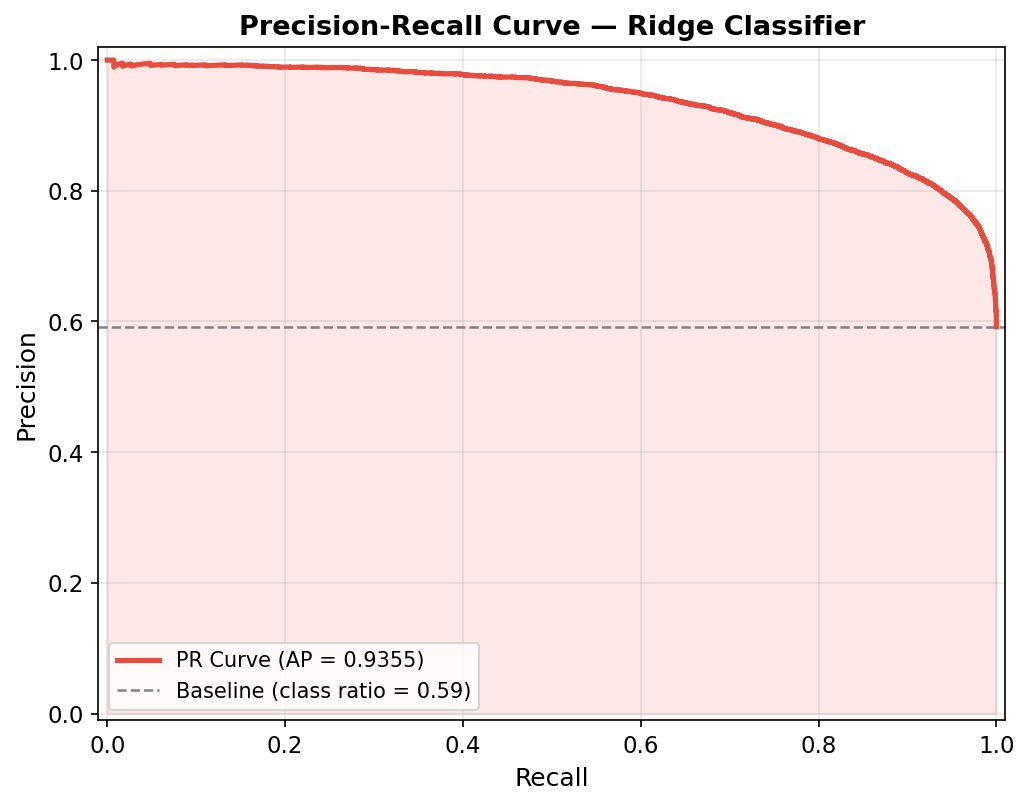

In [7]:
plot_pr_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

## Regularisation Path (Alpha vs Accuracy)

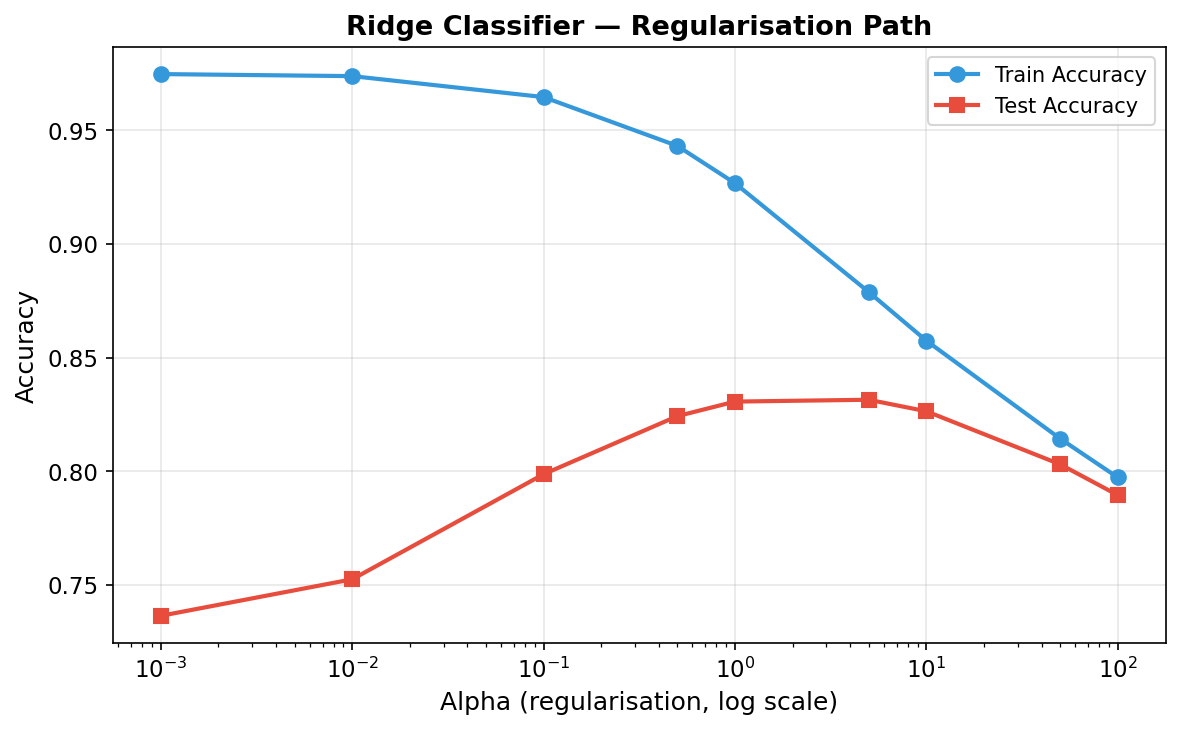

In [ ]:
alphas = [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0]
tr_accs, te_accs = [], []
for a in alphas:
    m = RidgeClassifier(alpha=a)
    m.fit(X_tr, y_train)
    tr_accs.append(accuracy_score(y_train, m.predict(X_tr)))
    te_accs.append(accuracy_score(y_test, m.predict(X_te)))

fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogx(alphas, tr_accs, 'o-', color='#3498db', lw=2, ms=7, label='Train Accuracy')
ax.semilogx(alphas, te_accs, 's-', color='#e74c3c', lw=2, ms=7, label='Test Accuracy')
ax.set_xlabel('Alpha (regularisation, log scale)')
ax.set_ylabel('Accuracy')
ax.set_title('Ridge Classifier — Regularisation Path')
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'ridge_reg_path.png'), dpi=150, bbox_inches='tight')
plt.show()

## Learning Curve

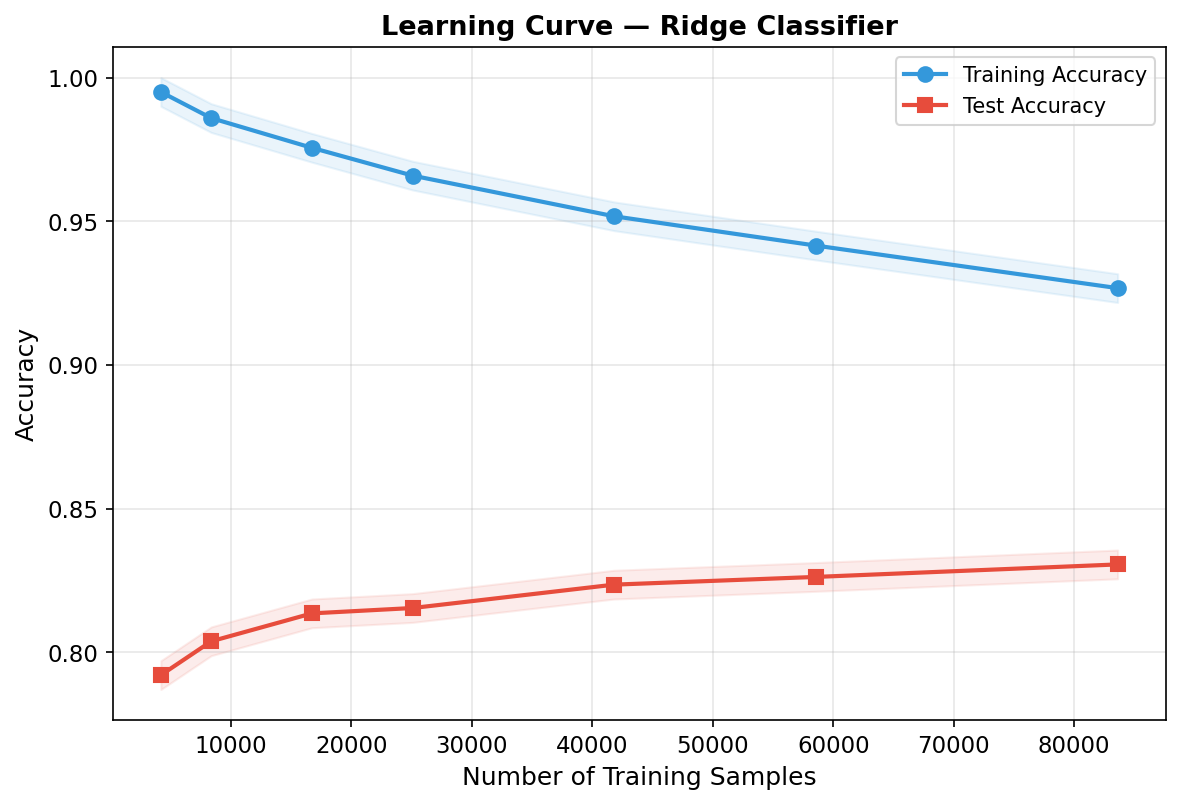

([4180, 8361, 16723, 25084, 41808, 58531, 83616],
 [0.994976076555024,
  0.9858868556392776,
  0.975542665789631,
  0.9658746611385743,
  0.9517317259854573,
  0.9415523397857546,
  0.9267365097588978],
 [0.7921071513991867,
  0.8038746711313083,
  0.8135852666826118,
  0.8154508490791677,
  0.8235828749103086,
  0.8262616598899785,
  0.8306146854819422])

In [ ]:
plot_learning_curve(model, X_tr, y_train, X_te, y_test, MODEL_NAME, FIGURES_DIR)